## Week 1 – Data Understanding & Exploratory Data Analysis (EDA)

During Week 1 of the FreshCart Multi-Store Demand Forecasting project, the focus was on understanding the sales dataset, examining its structure, and identifying data quality issues before proceeding with forecasting. The dataset was explored by inspecting its columns, data types, date range, store IDs, SKU IDs, and sales quantities.

Data quality checks were performed to identify missing values, duplicate records, and missing dates within the dataset. Date completeness was also examined to understand whether daily sales records were consistently available across the time period. The analysis was extended to individual store-SKU combinations to identify potential gaps in daily sales records.

Exploratory Data Analysis (EDA) was performed to understand sales patterns and demand behavior. Yearly sales were aggregated and visualized to compare total quantities sold across years. Additional analysis included monthly sales trends, store-wise sales comparisons, and identification of top-selling products (SKUs).

These analyses helped establish an initial understanding of demand patterns, sales variations across stores and products, and potential data quality issues that may affect forecasting accuracy.

### Week 1 Outcomes
- Understood the structure and characteristics of the sales dataset.
- Identified missing values, duplicate records, and date gaps.
- Analyzed yearly and monthly sales trends.
- Compared sales performance across different stores.
- Identified high-demand and low-demand products.
- Established a foundation for data preprocessing and demand forecasting in the upcoming weeks.

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [34]:
sales_2023 = pd.read_csv('sales_daily_2023.csv')

sales_2024 = pd.read_csv('sales_daily_2024.csv')

sales_2025 = pd.read_csv('sales_daily_2025.csv')

weather = pd.read_csv('weather_daily.csv')

stores = pd.read_csv('stores.csv')

products = pd.read_csv("products.csv")

festivals = pd.read_csv("festival_calendar_2023_2025.csv")

In [35]:
print("Sales 2023")
display(sales_2023.head())

print("Sales 2024")
display(sales_2024.head())

print("Sales 2025")
display(sales_2025.head())

Sales 2023


,date,store_id,sku_id,units_sold,selling_price,on_promo,discount_pct,closing_stock
0,2023-05-25,S07,P048,5,126.0,1,0.3,11.0
1,2023-09-13,S08,P013,6,99.0,0,0.0,6.0
2,2023-06-29,S04,P048,0,180.0,0,0.0,19.0
3,2023-01-25,S02,P027,7,30.0,0,0.0,32.0
4,2023-06-01,S04,P014,5,120.0,0,0.0,25.0


Sales 2024


,date,store_id,sku_id,units_sold,selling_price,on_promo,discount_pct,closing_stock
0,2024-08-18,S03,P042,7,58.3,0,0.0,24.0
1,2024-02-18,S03,P003,28,260.0,0,0.0,NaN
2,2024-06-30,S07,P041,32,22.0,0,0.0,NaN
3,2024-05-20,S08,P007,2,180.0,0,0.0,22.0
4,2024-01-28,S09,P031,1,120.0,0,0.0,19.0


Sales 2025


,date,store_id,sku_id,units_sold,selling_price,on_promo,discount_pct,closing_stock
0,2025-07-29,S02,P037,5,222.60,0,0.00,NaN
1,2025-08-24,S02,P014,28,127.20,0,0.00,15.0
2,2025-07-24,S02,P045,14,40.54,1,0.15,6.0
3,2025-05-03,S05,P045,11,47.70,0,0.00,7.0
4,2025-07-17,S07,P042,1,58.30,0,0.00,21.0


In [36]:
print("2023:", sales_2023.shape)
print("2024:", sales_2024.shape)
print("2025:", sales_2025.shape)
print("Weather:", weather.shape)

2023: (164804, 8)
2024: (167546, 8)
2025: (135070, 8)
Weather: (7028, 4)


In [37]:
print(sales_2023.columns)
print(sales_2024.columns)
print(sales_2025.columns)

Index(['date', 'store_id', 'sku_id', 'units_sold', 'selling_price', 'on_promo',
       'discount_pct', 'closing_stock'],
      dtype='object')
Index(['date', 'store_id', 'sku_id', 'units_sold', 'selling_price', 'on_promo',
       'discount_pct', 'closing_stock'],
      dtype='object')
Index(['date', 'store_id', 'sku_id', 'units_sold', 'selling_price', 'on_promo',
       'discount_pct', 'closing_stock'],
      dtype='object')


In [38]:
sales_2023.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 164804 entries, 0 to 164803
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   date           164804 non-null  object 
 1   store_id       164804 non-null  object 
 2   sku_id         164804 non-null  object 
 3   units_sold     164804 non-null  int64  
 4   selling_price  164804 non-null  float64
 5   on_promo       164804 non-null  int64  
 6   discount_pct   164804 non-null  float64
 7   closing_stock  90075 non-null   float64
dtypes: float64(3), int64(2), object(3)
memory usage: 10.1+ MB


In [39]:
sales_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167546 entries, 0 to 167545
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   date           167546 non-null  object 
 1   store_id       167546 non-null  object 
 2   sku_id         167546 non-null  object 
 3   units_sold     167546 non-null  int64  
 4   selling_price  167546 non-null  float64
 5   on_promo       167546 non-null  int64  
 6   discount_pct   167546 non-null  float64
 7   closing_stock  91190 non-null   float64
dtypes: float64(3), int64(2), object(3)
memory usage: 10.2+ MB


In [40]:
sales_2025.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 135070 entries, 0 to 135069
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   date           135070 non-null  object 
 1   store_id       135070 non-null  object 
 2   sku_id         135070 non-null  object 
 3   units_sold     135070 non-null  int64  
 4   selling_price  135070 non-null  float64
 5   on_promo       135070 non-null  int64  
 6   discount_pct   135070 non-null  float64
 7   closing_stock  72541 non-null   float64
dtypes: float64(3), int64(2), object(3)
memory usage: 8.2+ MB


In [41]:
print("sales 2023 Missing valuse:")
print(sales_2023.isnull().sum())
print("sales 2024 Missing valuse:")
print(sales_2024.isnull().sum())
print("sales 2025 Missing valuse:")
print(sales_2025.isnull().sum())

sales 2023 Missing valuse:
date                 0
store_id             0
sku_id               0
units_sold           0
selling_price        0
on_promo             0
discount_pct         0
closing_stock    74729
dtype: int64
sales 2024 Missing valuse:
date                 0
store_id             0
sku_id               0
units_sold           0
selling_price        0
on_promo             0
discount_pct         0
closing_stock    76356
dtype: int64
sales 2025 Missing valuse:
date                 0
store_id             0
sku_id               0
units_sold           0
selling_price        0
on_promo             0
discount_pct         0
closing_stock    62529
dtype: int64


In [42]:
print("sales_2023 Total Missing valuse:")
print(sales_2023.isnull().sum().sum())
print("sales_2024 Total Missing valuse:")
print(sales_2024.isnull().sum().sum())
print("sales_2025 Total Missing valuse:")
print(sales_2025.isnull().sum().sum())

sales_2023 Total Missing valuse:
74729
sales_2024 Total Missing valuse:
76356
sales_2025 Total Missing valuse:
62529


In [43]:
missing = pd.DataFrame({
    "Missing_Count 2023": sales_2023.isnull().sum(),
    "Missing_Percentage 2023": sales_2023.isnull().mean() * 100,
    "Missing_count 2024": sales_2024.isnull().sum(),
    "Missing_Percentage 2024": sales_2024.isnull().mean() * 100,
    "Missing_count 2025": sales_2025.isnull().sum(),
    "Missing_Percentage 2025": sales_2025.isnull().mean() * 100
})

print(missing)

               Missing_Count 2023  Missing_Percentage 2023  \
date                            0                 0.000000   
store_id                        0                 0.000000   
sku_id                          0                 0.000000   
units_sold                      0                 0.000000   
selling_price                   0                 0.000000   
on_promo                        0                 0.000000   
discount_pct                    0                 0.000000   
closing_stock               74729                45.344166   

               Missing_count 2024  Missing_Percentage 2024  \
date                            0                 0.000000   
store_id                        0                 0.000000   
sku_id                          0                 0.000000   
units_sold                      0                 0.000000   
selling_price                   0                 0.000000   
on_promo                        0                 0.000000   
discoun

In [44]:
print("Duplicates:", sales_2023.duplicated().sum())
print("Duplicates:", sales_2024.duplicated().sum())
print("Duplicates:", sales_2025.duplicated().sum())

Duplicates: 554
Duplicates: 546
Duplicates: 400


In [45]:
print(
    sales_2023.duplicated(
        subset=["date", "store_id", "sku_id"]
    ).sum()
)
print(
    sales_2024.duplicated(
        subset=["date", "store_id", "sku_id"]
    ).sum()
)
print(
    sales_2025.duplicated(
        subset=["date", "store_id", "sku_id"]
    ).sum()
)


554
546
400


In [46]:
print("Negative quantities:")
print(sales_2023[sales_2023["units_sold"] < 0])

print("Negative prices:")
print(sales_2023[sales_2023["selling_price"] < 0])

print("Negative closing stock:")
print(sales_2023[sales_2023["closing_stock"] < 0])

Negative quantities:
              date store_id sku_id  units_sold  selling_price  on_promo  \
1865    2023-03-02      S04   P006          -7          180.0         0   
3445    2023-06-11      S01   P048          -5          180.0         0   
5363    2023-02-19      S07   P035          -1          450.0         0   
5545    2023-04-26      S01   P012          -6           45.0         0   
6731    2023-09-04      S03   P027          -8           30.0         0   
...            ...      ...    ...         ...            ...       ...   
158799  2023-01-15      S09   P039          -2           60.0         0   
159962  2023-06-16      S06   P012          -3           45.0         0   
160009  2023-11-23      S08   P032          -1           60.0         0   
162285  2023-08-23      S03   P031         -55          120.0         0   
164602  2023-03-10      S08   P029          -9           99.0         0   

        discount_pct  closing_stock  
1865             0.0           20.0  
34

In [47]:
print("Negative quantities:")
print(sales_2024[sales_2024["units_sold"] < 0])

print("Negative prices:")
print(sales_2024[sales_2024["selling_price"] < 0])

print("Negative closing stock:")
print(sales_2024[sales_2024["closing_stock"] < 0])

Negative quantities:
              date store_id sku_id  units_sold  selling_price  on_promo  \
2245    2024-05-17      S08   P042          -3          55.00         0   
5855    2024-10-28      S09   P038          -2         104.94         0   
6607    2024-05-12      S01   P045         -44          45.00         0   
6683    2024-05-15      S08   P023          -3         210.00         0   
7173    2024-05-12      S09   P036          -1         180.00         0   
...            ...      ...    ...         ...            ...       ...   
159800  2024-01-26      S02   P048          -6         180.00         0   
162689  2024-07-19      S07   P016          -8         190.80         0   
165215  2024-08-21      S09   P003          -8         275.60         0   
165638  2024-11-05      S02   P034         -17          23.32         0   
166510  2024-07-23      S08   P022          -5         339.20         0   

        discount_pct  closing_stock  
2245             0.0            NaN  
58

In [48]:
print("Negative quantities:")
print(sales_2025[sales_2025["units_sold"] < 0])

print("Negative prices:")
print(sales_2025[sales_2025["selling_price"] < 0])

print("Negative closing stock:")
print(sales_2025[sales_2025["closing_stock"] < 0])

Negative quantities:
              date store_id sku_id  units_sold  selling_price  on_promo  \
135     2025-02-16      S10   P025          -5         190.80         0   
3417    2025-01-09      S01   P021         -20         153.70         0   
4003    2025-02-26      S06   P038          -3         104.94         0   
4055    2025-05-27      S02   P037          -5         222.60         0   
4392    2025-05-18      S06   P034         -36          23.32         0   
...            ...      ...    ...         ...            ...       ...   
127365  2025-01-27      S01   P026          -6         477.00         0   
129853  2025-04-22      S04   P004          -9          58.30         0   
130137  2025-02-06      S01   P018         -22          31.80         0   
130746  2025-08-10      S07   P027         -10          31.80         0   
131282  2025-01-29      S06   P013          -3         104.94         0   

        discount_pct  closing_stock  
135              0.0            NaN  
34

In [49]:
sales_2023.describe()

,units_sold,selling_price,on_promo,discount_pct,closing_stock
count,164804.000000,164804.000000,164804.000000,164804.000000,90075.000000
mean,12.127060,147.038203,0.052960,0.009246,25.273827
std,22.950084,127.897859,0.223954,0.043867,24.638299
min,-103.000000,15.400000,0.000000,0.000000,0.000000
25%,3.000000,55.000000,0.000000,0.000000,11.000000
50%,7.000000,99.000000,0.000000,0.000000,18.000000
75%,14.000000,180.000000,0.000000,0.000000,31.000000
max,4300.000000,560.000000,1.000000,0.300000,212.000000


In [50]:
sales_2024.describe()

,units_sold,selling_price,on_promo,discount_pct,closing_stock
count,167546.000000,167546.000000,167546.000000,167546.000000,91190.000000
mean,12.496729,166.168425,0.051502,0.009146,24.634269
std,20.283817,280.243470,0.221021,0.043627,23.902528
min,-98.000000,15.400000,0.000000,0.000000,0.000000
25%,3.000000,55.000000,0.000000,0.000000,11.000000
50%,7.000000,104.940000,0.000000,0.000000,18.000000
75%,15.000000,190.800000,0.000000,0.000000,30.000000
max,2600.000000,4500.000000,1.000000,0.300000,217.000000


In [51]:
sales_2025.describe()

,units_sold,selling_price,on_promo,discount_pct,closing_stock
count,135070.000000,135070.000000,135070.000000,135070.000000,72541.000000
mean,12.704242,156.661242,0.049056,0.008409,24.154781
std,40.801452,136.449759,0.215986,0.041702,23.070500
min,-111.000000,16.320000,0.000000,0.000000,0.000000
25%,3.000000,58.300000,0.000000,0.000000,11.000000
50%,7.000000,104.940000,0.000000,0.000000,18.000000
75%,15.000000,190.800000,0.000000,0.000000,30.000000
max,12000.000000,593.600000,1.000000,0.300000,211.000000


In [52]:
sales_2023["date"] = pd.to_datetime(
    sales_2023["date"],
    errors="coerce"
)
sales_2024["date"] = pd.to_datetime(
    sales_2024["date"],
    errors="coerce"
)
sales_2025["date"] = pd.to_datetime(
    sales_2025["date"],
    errors="coerce"
)

In [53]:
print("Starting Date 2023:", sales_2023["date"].min())
print("Ending Date 2023:", sales_2023["date"].max())
print("Starting Date 2024:", sales_2024["date"].min())
print("Ending Date 2024:", sales_2024["date"].max())
print("Starting Date 2025:", sales_2025["date"].min())
print("Ending Date 2025:", sales_2025["date"].max())

Starting Date 2023: 2023-01-01 00:00:00
Ending Date 2023: 2023-12-31 00:00:00
Starting Date 2024: 2024-01-01 00:00:00
Ending Date 2024: 2024-12-31 00:00:00
Starting Date 2025: 2025-01-01 00:00:00
Ending Date 2025: 2025-09-30 00:00:00


In [54]:
all_dates = pd.date_range(
    start=sales_2023["date"].min(),
    end=sales_2023["date"].max(),
    freq="D"
)

existing_dates = sales_2023["date"].dropna().unique()

missing_dates = set(all_dates) - set(existing_dates)

print("Missing dates:", len(missing_dates))
print(sorted(missing_dates)[:20])

Missing dates: 0
[]


In [55]:
all_dates = pd.date_range(
    start=sales_2024["date"].min(),
    end=sales_2024["date"].max(),
    freq="D"
)

existing_dates = sales_2024["date"].dropna().unique()

missing_dates = set(all_dates) - set(existing_dates)

print("Missing dates:", len(missing_dates))
print(sorted(missing_dates)[:20])

Missing dates: 0
[]


In [56]:
all_dates = pd.date_range(
    start=sales_2025["date"].min(),
    end=sales_2025["date"].max(),
    freq="D"
)

existing_dates = sales_2025["date"].dropna().unique()

missing_dates = set(all_dates) - set(existing_dates)

print("Missing dates:", len(missing_dates))
print(sorted(missing_dates)[:20])

Missing dates: 0
[]


In [57]:
sales = pd.concat(
    [sales_2023, sales_2024, sales_2025],
    ignore_index=True
)

print(sales.shape)

(467420, 8)


In [58]:
print(sales.head())
print(sales.info())
print(sales.isnull().sum())

        date store_id sku_id  units_sold  selling_price  on_promo  \
0 2023-05-25      S07   P048           5          126.0         1   
1 2023-09-13      S08   P013           6           99.0         0   
2 2023-06-29      S04   P048           0          180.0         0   
3 2023-01-25      S02   P027           7           30.0         0   
4 2023-06-01      S04   P014           5          120.0         0   

   discount_pct  closing_stock  
0           0.3           11.0  
1           0.0            6.0  
2           0.0           19.0  
3           0.0           32.0  
4           0.0           25.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 467420 entries, 0 to 467419
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   date           467420 non-null  datetime64[ns]
 1   store_id       467420 non-null  object        
 2   sku_id         467420 non-null  object        
 3   units_sold  

year
2023    1998588
2024    2093777
2025    1715962
Name: units_sold, dtype: int64


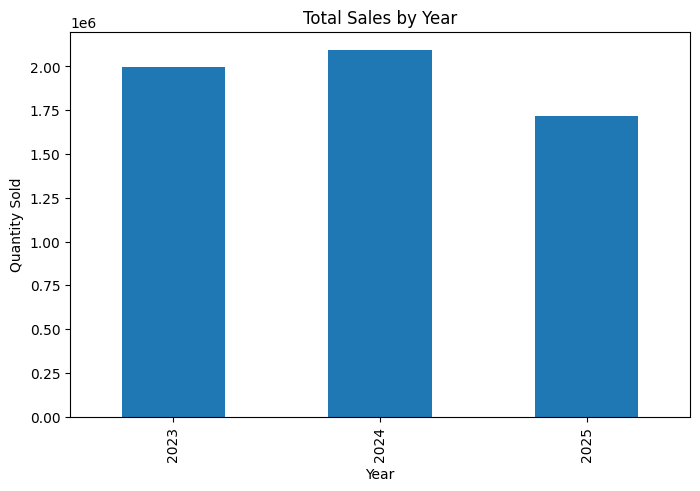

In [59]:
sales["year"] = sales["date"].dt.year

yearly_sales = sales.groupby("year")["units_sold"].sum()

print(yearly_sales)

yearly_sales.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Total Sales by Year")
plt.xlabel("Year")
plt.ylabel("Quantity Sold")
plt.show()

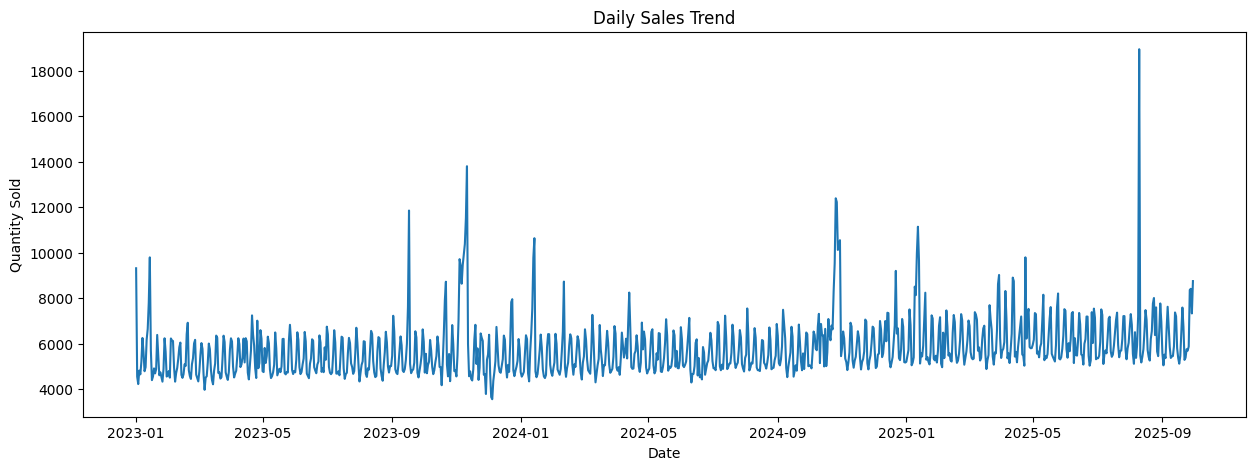

In [60]:
daily_sales = sales.groupby("date")["units_sold"].sum()

plt.figure(figsize=(15, 5))

plt.plot(daily_sales)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Quantity Sold")

plt.show()

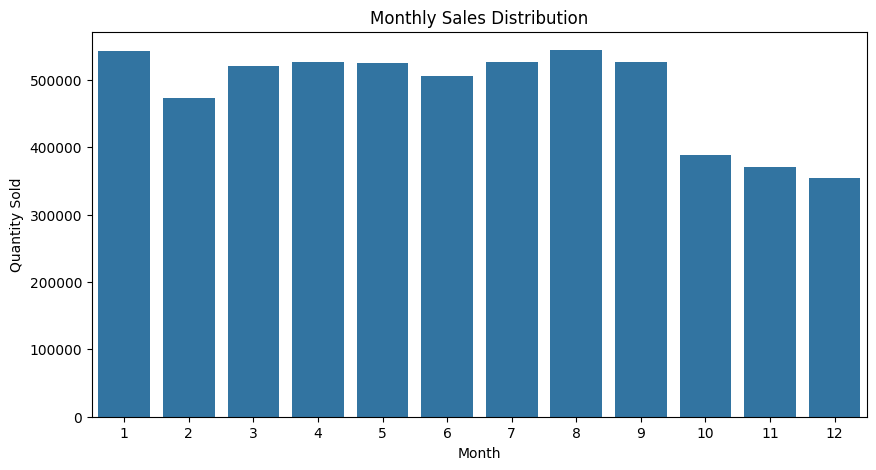

In [61]:
sales["month"] = sales["date"].dt.month

monthly_sales = sales.groupby("month")["units_sold"].sum()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_sales.index,
    y=monthly_sales.values
)

plt.title("Monthly Sales Distribution")
plt.xlabel("Month")
plt.ylabel("Quantity Sold")

plt.show()

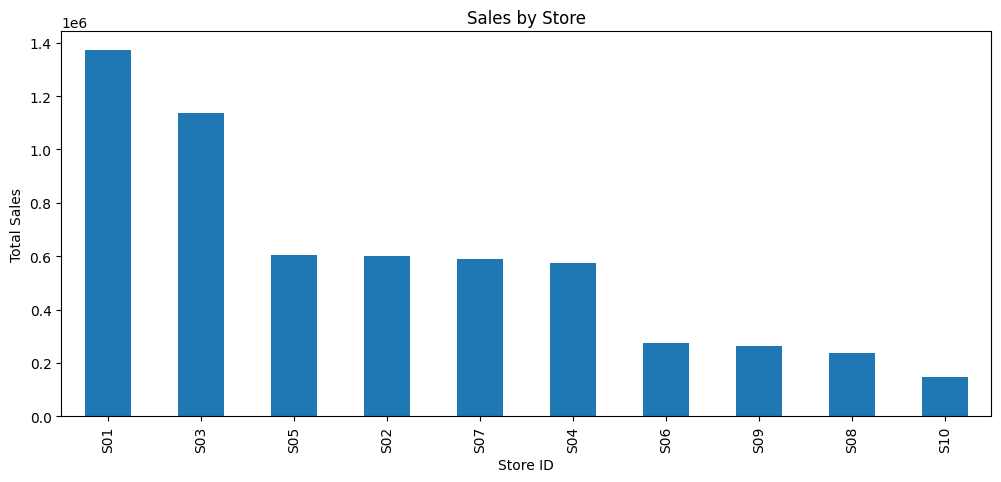

In [62]:
store_sales = sales.groupby("store_id")["units_sold"].sum()

plt.figure(figsize=(12, 5))

store_sales.sort_values(ascending=False).plot(kind="bar")

plt.title("Sales by Store")
plt.xlabel("Store ID")
plt.ylabel("Total Sales")

plt.show()

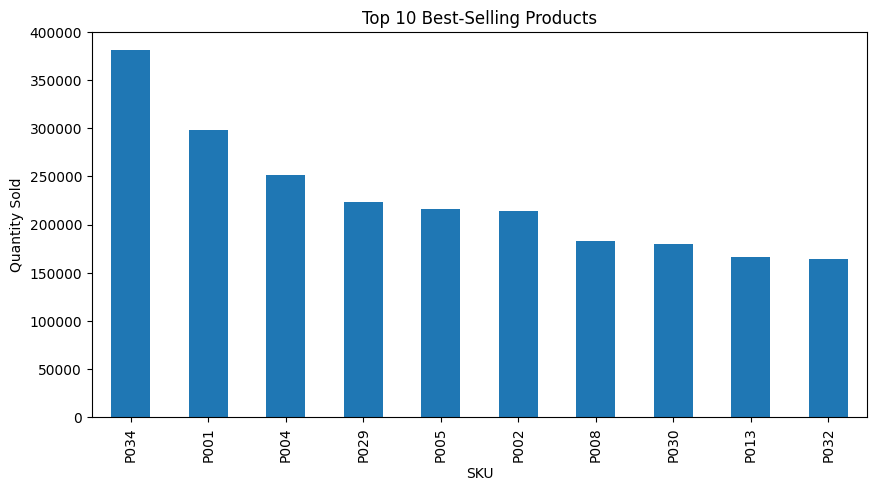

In [63]:
top_skus = sales.groupby("sku_id")["units_sold"].sum().sort_values(ascending=False).head(10)

top_skus.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Best-Selling Products")
plt.xlabel("SKU")
plt.ylabel("Quantity Sold")
plt.show()

In [64]:
display(festivals.head())

print(festivals.columns)

,date,festival
0,2023-01-15,Pongal
1,2023-04-14,Tamil New Year
2,2023-04-22,Ramzan
3,2023-09-18,Vinayaka Chaturthi
4,2023-10-23,Ayudha Pooja


Index(['date', 'festival'], dtype='object')


In [65]:
print(festivals["festival"].unique())

['Pongal' 'Tamil New Year' 'Ramzan' 'Vinayaka Chaturthi' 'Ayudha Pooja'
 'Deepavali' 'Karthigai Deepam' 'Christmas']


In [66]:
quality_report = pd.DataFrame({
    "Column": sales.columns,
    "Data_Type": sales.dtypes.astype(str).values,
    "Missing_Values": sales.isnull().sum().values,
    "Missing_Percentage": (
        sales.isnull().mean() * 100
    ).values,
    "Unique_Values": sales.nunique().values
})

display(quality_report)

quality_report.to_csv(
    "week1_data_quality_report.csv",
    index=False
)

,Column,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
0,date,datetime64[ns],0,0.000000,1004
1,store_id,object,0,0.000000,10
2,sku_id,object,0,0.000000,50
3,units_sold,int64,0,0.000000,317
4,selling_price,float64,0,0.000000,213
5,on_promo,int64,0,0.000000,2
6,discount_pct,float64,0,0.000000,7
7,closing_stock,float64,213614,45.700655,215
8,year,int32,0,0.000000,3
9,month,int32,0,0.000000,12
